# Projet - Classification du rythme cardiaque issu d'ECG


Ce jeu de données est composé d'une collections de signaux de battements cardiaques provenant d'un jeu de données célèbres dans le domaine de la classification des battements cardiaques, le jeu de données sur l'arythmie du MIT-BIH.

Les signaux correspondent à des formes d'électrocardiogramme (ECG) de battements cardiaques pour le cas normal et les cas affectés par différentes arythmies et infarctus du myocarde. Ces signaux sont prétraités et segmentés, chaque segment correspondant à un battement cardiaque.

<img src="./DataECG.png" width="800" height="600">

On distingue 5 battements cardiaques différents : Battements normaux', 'Battements inconnus', 'Battements ectopiques ventriculaires', 'Battements ectopiques supraventriculaires' et 'Battements de fusion'.

De ces signaux, on extrait des caractéristiques par la librairie TSFEL - *Time Series Features Extraction Library* (https://tsfel.readthedocs.io/en/latest/index.html)

Les 156 caractéristiques extraites sont divisées selon les domaines :
- temporel avec 31 caractéristiques comme l'entropie, Max, Min, Absolute Energy ...
- statistique avec 14 caractéristiques comme écart moyen absolu, écart médian, variance, Kurtosis...
- spectral  avec 111 caractéristiques comme les coefficients FFT par bande de fréquence, ondelettes...

Lien vers le papier expliquant TSFEL : https://www.sciencedirect.com/science/article/pii/S2352711020300017

In [ ]:
# Librairies utiles
import numpy as np
import sklearn
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score

# Chargement des données d'apprentissage et de test

In [2]:
# Chargement des données d'apprentissage
DataFeatureApp=np.load('./DataApp.npy')
LabelApp=np.load('./LabelApp.npy')
print('Taille de la base d apprentissage :', DataFeatureApp.shape, LabelApp.shape)

# Chargement des données de test
DataFeatureTest=np.load('./DataTest.npy')
LabelTest=np.load('./LabelTest.npy')
print('Taille de la base d apprentissage :', DataFeatureTest.shape, LabelTest.shape)

Taille de la base d apprentissage : (5000, 156) (5000,)
Taille de la base d apprentissage : (750, 156) (750,)


# Chargement des variables issues *TSFEL*

In [3]:
ListeVariablesStat=np.load('./ListeVariableStat.npy',allow_pickle=True)
print('Nombre de variables statistiques :',ListeVariablesStat.shape)
print('Liste Variables Statistiques :', ListeVariablesStat)

ListeVariablesTemps=np.load('./ListeVariableTemps.npy',allow_pickle=True)
print('Nombre de variables temporelles :',ListeVariablesTemps.shape)
print('Liste Variables Temporelles :',ListeVariablesTemps)

ListeVariablesSpectral=np.load('./ListeVariableSpectral.npy',allow_pickle=True)
print('Nombre de variables spectrales :',ListeVariablesSpectral.shape)
print('Liste Variables Spectrales :',ListeVariablesSpectral)

AllNames = np.concatenate([ListeVariablesStat,ListeVariablesTemps,ListeVariablesSpectral])
print(AllNames.shape,DataFeatureApp.shape)



Nombre de variables statistiques : (31,)
Liste Variables Statistiques : ['0_Absolute energy' '0_Average power' '0_ECDF Percentile Count_0'
 '0_ECDF Percentile Count_1' '0_ECDF Percentile_0' '0_ECDF Percentile_1'
 '0_ECDF_0' '0_ECDF_1' '0_ECDF_2' '0_ECDF_3' '0_ECDF_4' '0_ECDF_5'
 '0_ECDF_6' '0_ECDF_7' '0_ECDF_8' '0_ECDF_9' '0_Entropy'
 '0_Histogram mode' '0_Interquartile range' '0_Kurtosis' '0_Max' '0_Mean'
 '0_Mean absolute deviation' '0_Median' '0_Median absolute deviation'
 '0_Min' '0_Peak to peak distance' '0_Root mean square' '0_Skewness'
 '0_Standard deviation' '0_Variance']
Nombre de variables temporelles : (14,)
Liste Variables Temporelles : ['0_Area under the curve' '0_Autocorrelation' '0_Centroid'
 '0_Mean absolute diff' '0_Mean diff' '0_Median absolute diff'
 '0_Median diff' '0_Negative turning points' '0_Neighbourhood peaks'
 '0_Positive turning points' '0_Signal distance' '0_Slope'
 '0_Sum absolute diff' '0_Zero crossing rate']
Nombre de variables spectrales : (111,)
Liste 

### Fonctions pour réaliser une table de correspondance entre le label des approches non supervisées et le label réel

In [4]:
def retrieve_info(cluster_labels,y_train):
 #Associe l'étiquette la plus probable à chaque groupe dans le modèle KMeans.
 #Résultats : dictionnaire des clusters associés à chaque étiquette.

# Initialisation
  reference_labels = np.zeros((len(np.unique(cluster_labels)),1))
# Loop pour chaque label
  for i in range(len(np.unique(cluster_labels))):
    index = np.where(cluster_labels == i,1,0)
    num = np.bincount(y_train[index==1]).argmax()
    reference_labels[i] = num
  return reference_labels

def correspondance(y_pred_kmeans,y_train):
  # Correspondance entre la partition et les classes de la vérité terrain
  reference_labels = retrieve_info(y_pred_kmeans,y_train)
  number_labels = np.zeros(len(y_pred_kmeans))
  for i in range(len(y_pred_kmeans)):
    number_labels[i] = reference_labels[y_pred_kmeans[i]]
  return number_labels


In [55]:
DataAppStat = DataFeatureApp[:,0:31]
DataTestStat = DataFeatureTest[:,0:31]
print(DataAppStat.shape)

DataAppTemps = DataFeatureApp[:,31:45]
DataTestTemps = DataFeatureTest[:,31:45]
print(DataAppTemps.shape)

DataAppSpec = DataFeatureApp[:,45:156]
DataTestSpec = DataFeatureTest[:,45:156]
print(DataAppSpec.shape)

DataAppAll = [DataFeatureApp, DataAppStat, DataAppTemps, DataAppSpec]
DataTestAll = [DataFeatureTest, DataTestStat, DataTestTemps, DataTestSpec]
titleAll = ["Tous", "Statistique", "Temporelle", "Spectral"]

(5000, 31)
(5000, 14)
(5000, 111)


# Partie I : Classification des battements cardiaques sans prétraitement

Réaliser une classification des battements cardiaques par une méthode d'apprentissage supervisé et une méthode d'apprentissage non supervisé de votre choix en utilisant soit les codes des TP précédents, soit en utilisant la librairie *scikit-learn*.

Pour chaque résultat obtenu, calculer la matrice de confusion et interpréter les résultats.


## Méthodes non supervisées

Indiquer quelles sont les 2 méthodes non supervisées de votre choix et calculer la matrice de confusion associée.

In [34]:
DataFull = []
for k in range(len(DataAppAll)):
    DataFull.append(np.concatenate((DataAppAll[k], DataTestAll[k]), axis=0))
LabelFull = np.concatenate((LabelApp, LabelTest), axis=0)

C:\Users\flori\AppData\Local\Temp\ipykernel_27712\2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred_kmeans[i]]
C:\Users\flori\AppData\Local\Temp\ipykernel_27712\2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred_kmeans[i]]
C:\Users\flori\AppData\Local\Temp\ipykernel_27712\2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = 

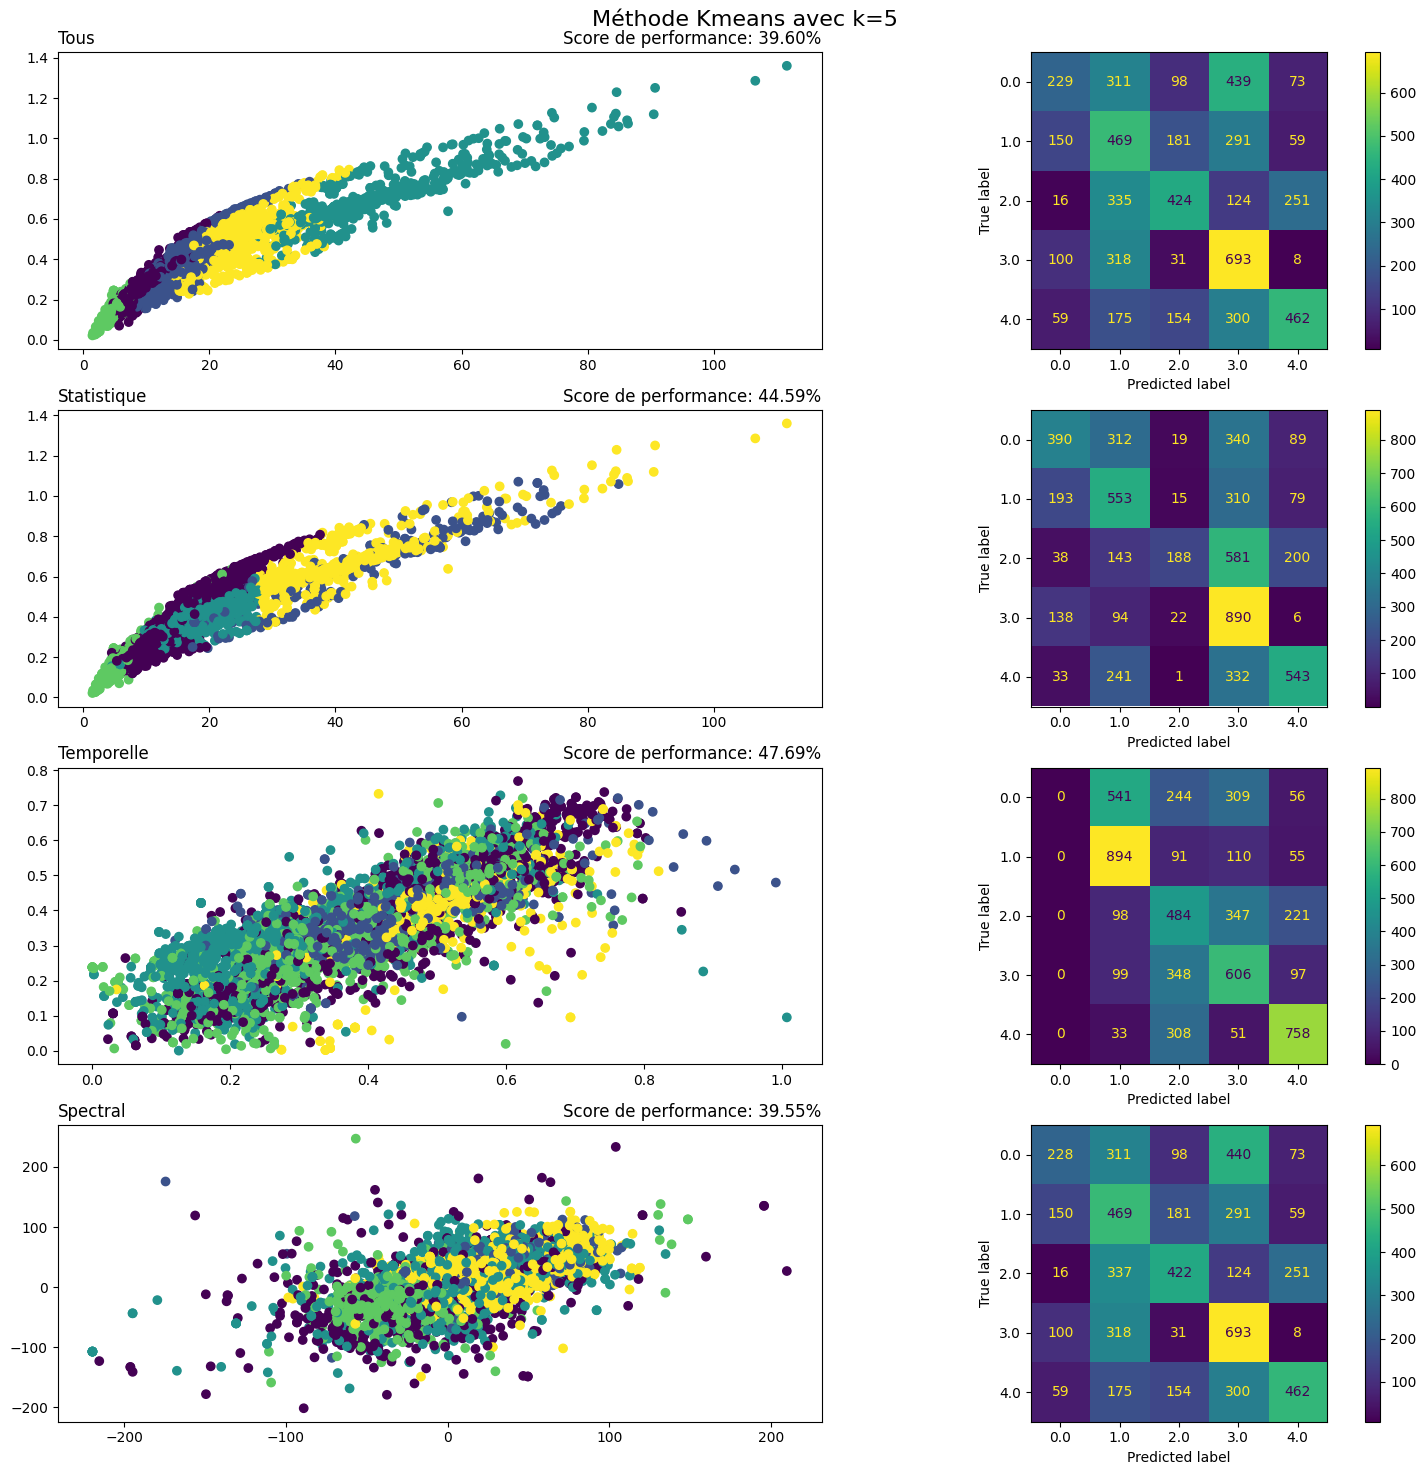

In [93]:
# Première méthode: K-means
from sklearn.cluster import KMeans

fig, ax = plt.subplots(len(DataAppAll), 2, figsize=(15,15))
for k in range(len(DataAppAll)):
    y_pred = KMeans(n_clusters=5, init='random').fit_predict(DataFull[k])
    y_label_clusturing = correspondance(y_pred,LabelFull.astype(np.int64))
    
    ax[k][0].scatter(DataFull[k][:, 0], DataFull[k][:, 1], c=y_pred) # Affichage des clusters
    ax[k][0].set_title(f"{titleAll[k]}", loc="left")
    ax[k][0].set_title(f"Score de performance: {accuracy_score(LabelFull, y_label_clusturing):.2%}", loc="right") # Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
    ConfusionMatrixDisplay.from_predictions(LabelFull, y_label_clusturing, ax=ax[k][1]) # Calcul de la matrice de confusion

fig.suptitle("Méthode Kmeans avec k=5", fontsize=16)
plt.tight_layout()
plt.show()

C:\Users\flori\AppData\Local\Temp\ipykernel_27712\2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred_kmeans[i]]
C:\Users\flori\AppData\Local\Temp\ipykernel_27712\2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred_kmeans[i]]
C:\Users\flori\AppData\Local\Temp\ipykernel_27712\2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = 

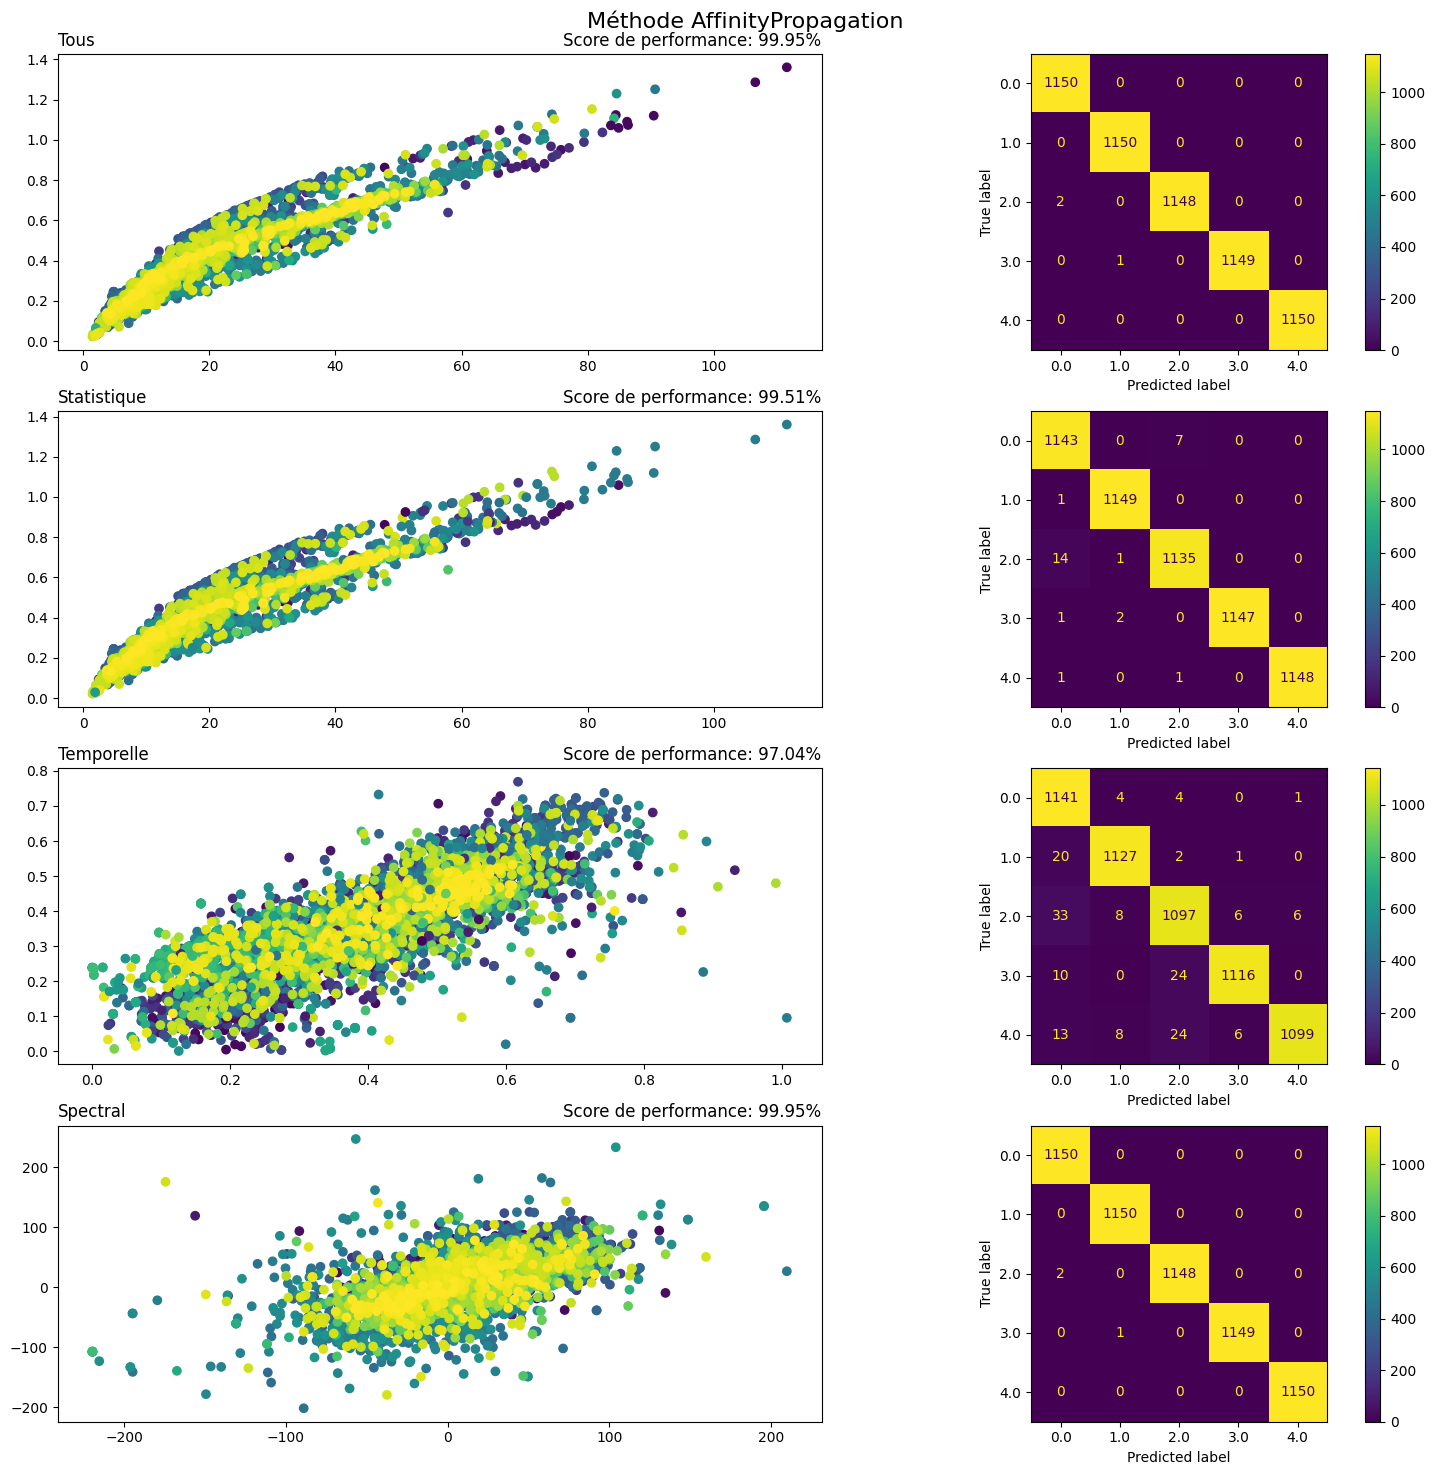

In [92]:
# Seconde méthode: AffinityPropagation
from sklearn.cluster import AffinityPropagation

fig, ax = plt.subplots(len(DataAppAll), 2, figsize=(15,15))
for k in range(len(DataAppAll)):
    y_pred = AffinityPropagation(max_iter=80, convergence_iter=1, random_state=42).fit_predict(DataFull[k])
    y_label_clusturing = correspondance(y_pred,LabelFull.astype(np.int64))

    ax[k][0].scatter(DataFull[k][:, 0], DataFull[k][:, 1], c=y_pred) # Affichage des clusters
    ax[k][0].set_title(f"{titleAll[k]}", loc="left")
    ax[k][0].set_title(f"Score de performance: {accuracy_score(LabelFull, y_label_clusturing):.2%}", loc="right") # Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
    ConfusionMatrixDisplay.from_predictions(LabelFull, y_label_clusturing, ax=ax[k][1]) # Calcul de la matrice de confusion

fig.suptitle("Méthode AffinityPropagation", fontsize=16)
plt.tight_layout()
plt.show()

## Méthodes supervisées  :
indiquer quelles sont les 2 méthodes supervisées de votre choix et calculer la matrice de confusion associée.

In [99]:
X_train = []
X_test = []
for k in range(len(DataAppAll)):
    X_train.append(DataAppAll[k])
    X_test.append(DataTestAll[k])
    print('Dimension de la base apprentissage',titleAll[k],':',X_train[k].shape)
    print('Dimension de la base test',titleAll[k],':',X_test[k].shape)

y_train = LabelApp
y_test = LabelTest


Dimension de la base apprentissage Tous : (5000, 156)
Dimension de la base test Tous : (750, 156)
Dimension de la base apprentissage Statistique : (5000, 31)
Dimension de la base test Statistique : (750, 31)
Dimension de la base apprentissage Temporelle : (5000, 14)
Dimension de la base test Temporelle : (750, 14)
Dimension de la base apprentissage Spectral : (5000, 111)
Dimension de la base test Spectral : (750, 111)


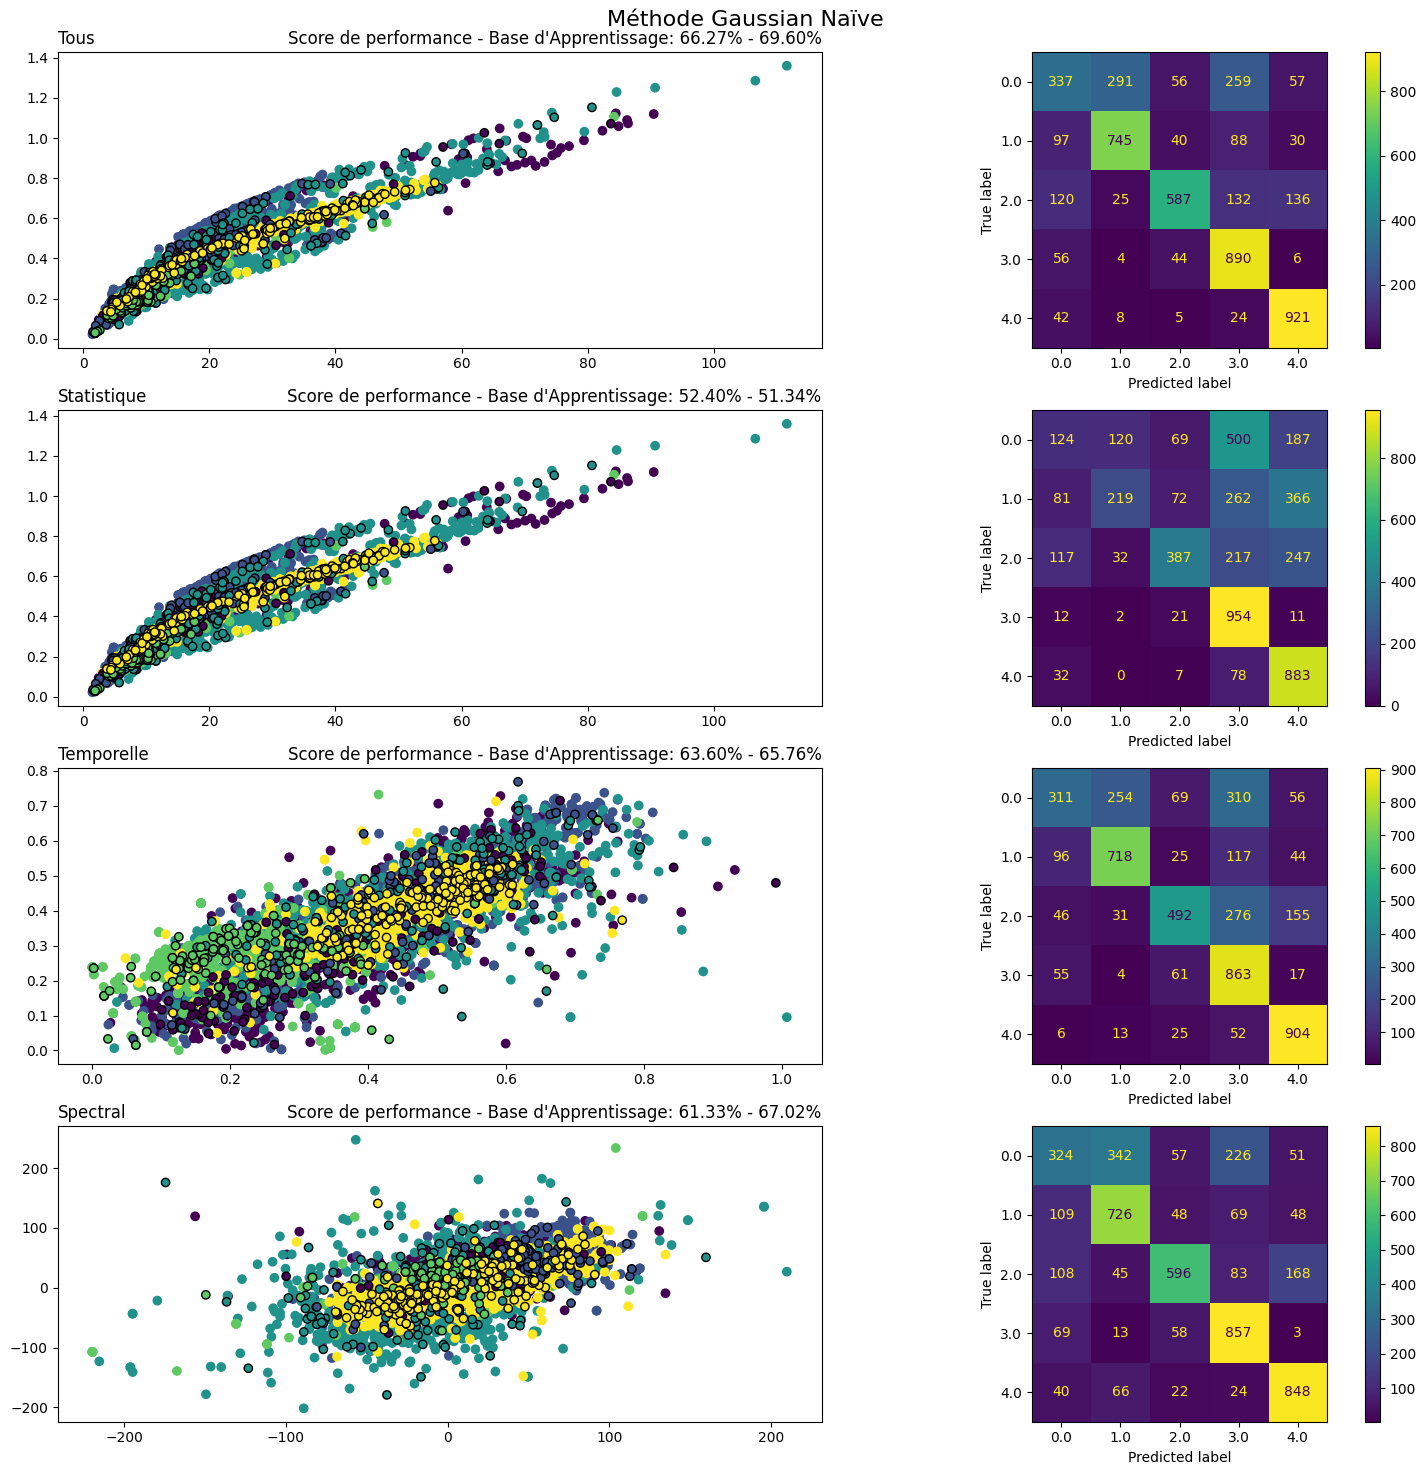

In [94]:
from sklearn.naive_bayes import GaussianNB

fig, ax = plt.subplots(len(DataAppAll), 2, figsize=(15,15))
for k in range(len(DataAppAll)):
    # chargement du modèle et de ses paramètres
    clf = GaussianNB()
    # Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
    # c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
    clf.fit(X_train[k], y_train)
    y_pred=clf.predict(X_test[k]) # Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
    y_pred_train=clf.predict(X_train[k]) # Evaluation du modèle appris sur la base d'apprentissage

    ax[k][0].scatter(X_train[k][:, 0], X_train[k][:, 1], c=y_train)
    ax[k][0].scatter(X_test[k][:, 0], X_test[k][:, 1], c=y_test, edgecolor="k")
    ax[k][0].set_title(f"{titleAll[k]}", loc="left")
    ax[k][0].set_title(f"Score de performance - Base d'Apprentissage: {accuracy_score(y_test, y_pred):.2%} - {accuracy_score(y_train, y_pred_train):.2%}", loc="right")
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train, ax=ax[k][1]) # Calcul de la matrice de confusion

fig.suptitle("Méthode Gaussian Naïve", fontsize=16)
plt.tight_layout()
plt.show()

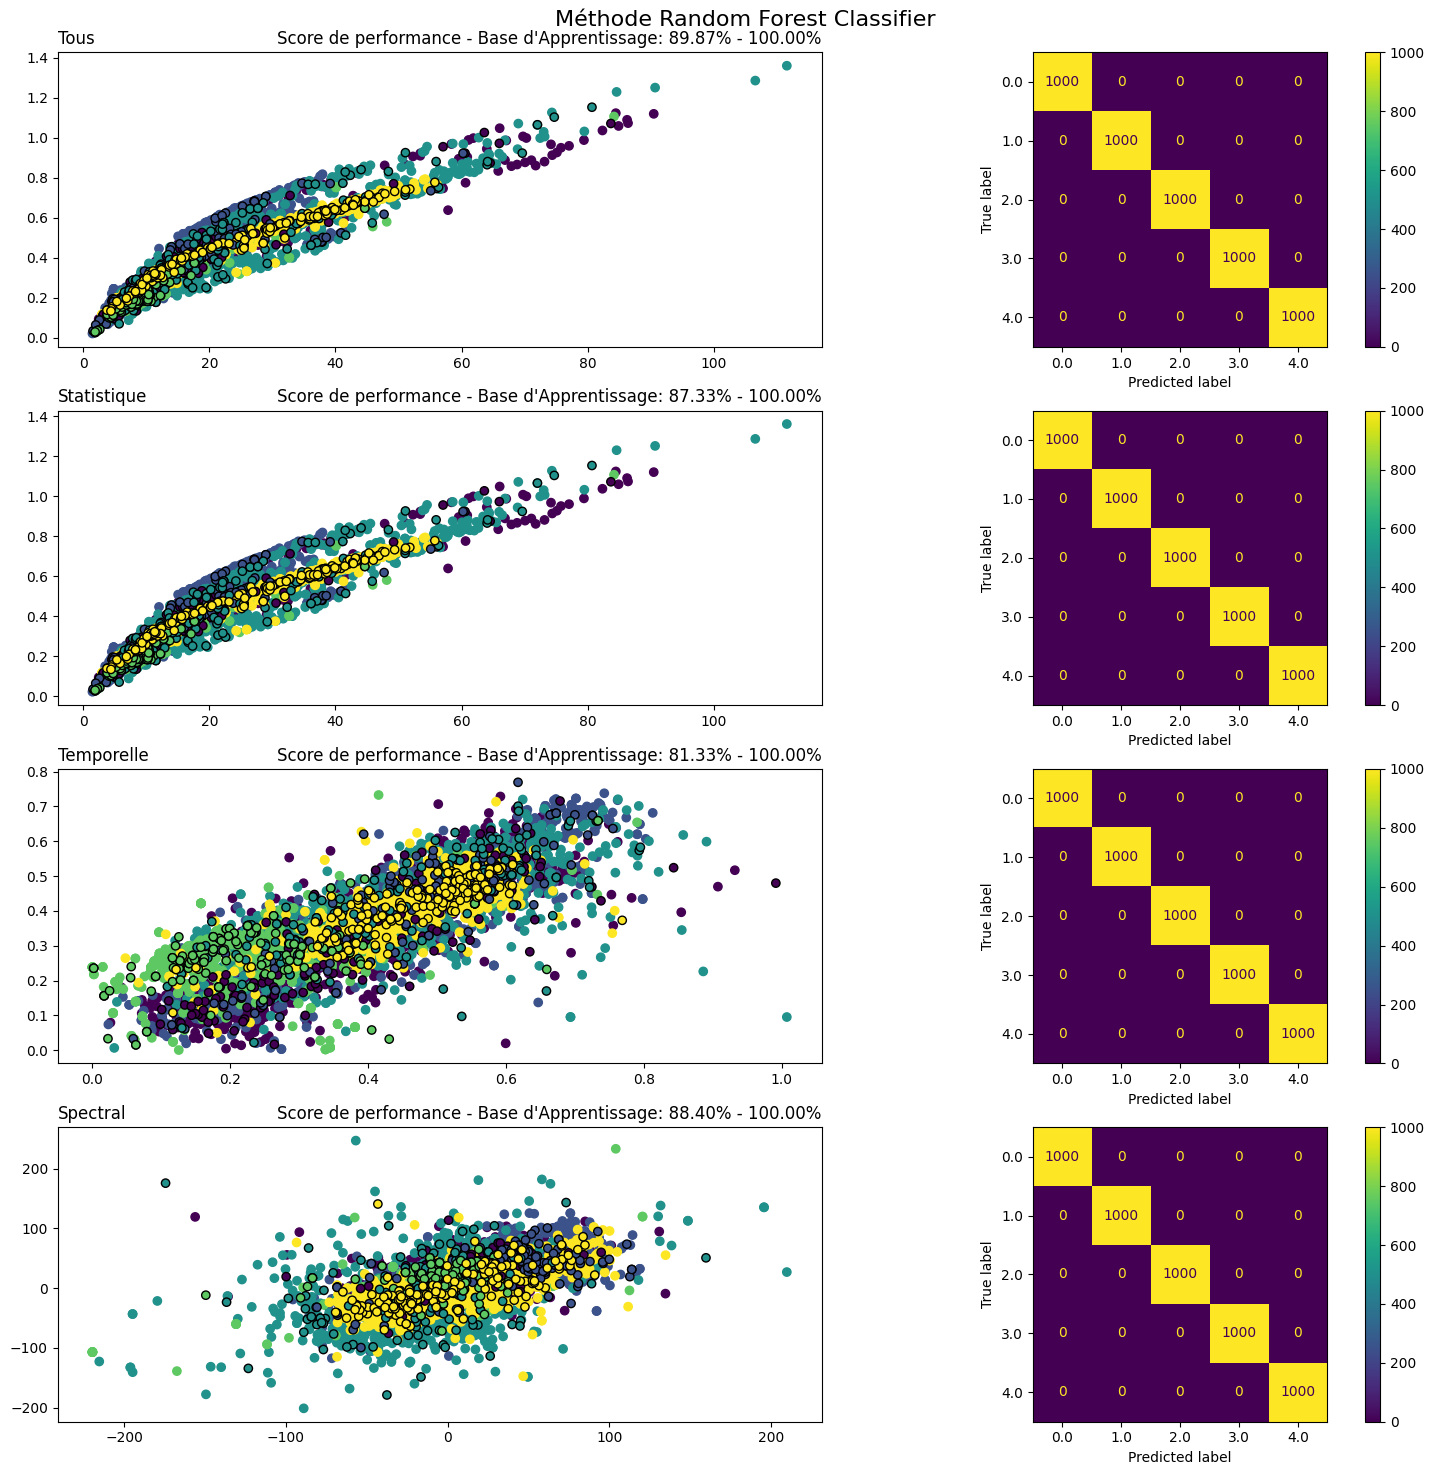

In [101]:
from sklearn.ensemble import RandomForestClassifier

fig, ax = plt.subplots(len(DataAppAll), 2, figsize=(15,15))
for k in range(len(DataAppAll)):
    # chargement du modèle et de ses paramètres
    clf = RandomForestClassifier(n_jobs=-1, criterion='entropy', max_features='log2', bootstrap=False, n_estimators=156, random_state=42)
    # Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
    # c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
    clf.fit(X_train[k], y_train)
    y_pred=clf.predict(X_test[k]) # Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
    y_pred_train=clf.predict(X_train[k]) # Evaluation du modèle appris sur la base d'apprentissage 
    
    ax[k][0].scatter(X_train[k][:, 0], X_train[k][:, 1], c=y_train)
    ax[k][0].scatter(X_test[k][:, 0], X_test[k][:, 1], c=y_test, edgecolor="k")
    ax[k][0].set_title(f"{titleAll[k]}", loc="left")
    ax[k][0].set_title(f"Score de performance - Base d'Apprentissage: {accuracy_score(y_test, y_pred):.2%} - {accuracy_score(y_train, y_pred_train):.2%}", loc="right")
    ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train, ax=ax[k][1]) # Calcul de la matrice de confusion

fig.suptitle("Méthode Random Forest Classifier", fontsize=16)
plt.tight_layout()
plt.show()

# Partie II : classification des battements cardiaques avec prétraitement par ACP

## Méthode supervisée avec réduction de dimension par ACP sur l'ensemble d'apprentissage
Réaliser une ACP sur l'ensemble d'apprentissage pour réduire la dimension, visualiser les données
puis projeter les données de l'ensemble de test dans la base de l'ACP.

Indiquer quelles sont les 3 méthodes supervisées de votre choix et calculer la matrice de confusion associée (confusion_matrix) et le score de performance (accuracy_score)

In [6]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

## Méthode non supervisée avec réduction de dimension par ACP sur l'ensemble des données

Réaliser une ACP sur l'ensemble des données et indiquer quelles sont les 2 méthodes non supervisées de votre choix et calculer la matrice de confusion associée (confusion_matrix) et le score de performance (accuracy_score)

(156, 156)
(156, 2)


/tmp/ipykernel_1070666/2636278578.py:12: ComplexWarning: Casting complex values to real discards the imaginary part
  principalAxes[:,i]=eig_vecs[:,i]


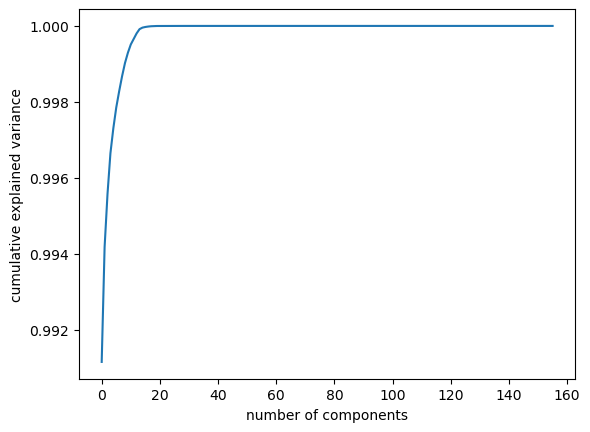

(5000, 156)


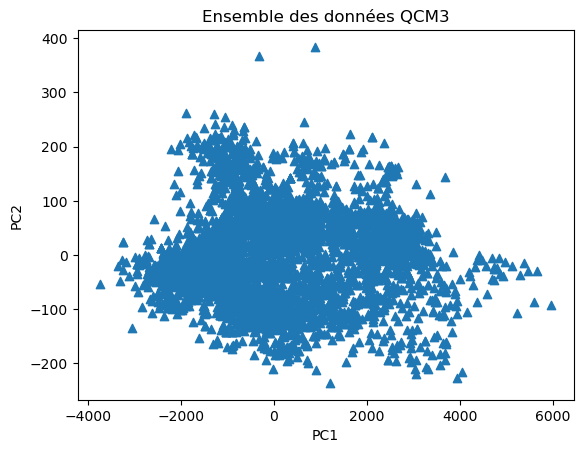

In [9]:
# Calcul de la matrice de confusion
n_components = 2
pca = PCA(n_components)
cov_mat = np.cov(np.transpose(DataFeatureApp))
# Dimension de la matrice de variance-covariance
print(cov_mat.shape)
# Extraction des valeurs propres et vecteurs propres
eig_vals,eig_vecs = np.linalg.eig(cov_mat)
# Définition des axes principaux
principalAxes=np.zeros((DataFeatureApp.shape[1],n_components))
for i in range(n_components):
    principalAxes[:,i]=eig_vecs[:,i]

# Dimension des axes principaux
print(principalAxes.shape)
pca = PCA().fit(DataFeatureApp)
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('number of components')
plt.ylabel('cumulative explained variance')
plt.show()
# Calcul des composantes principales c'est-à-dire les coefficients de projection des données 
# dans le nouveau repère défini par les axes principaux
principalComponents = pca.fit_transform(DataFeatureApp)
principalComponentsTest = pca.transform(DataFeatureTest)

# Dimension des composantes principales
print(principalComponents.shape)

# aAffichage des points
plt.scatter(principalComponents[:, 0], principalComponents[:, 1],marker='^')
plt.title("Ensemble des données QCM3")
plt.xlabel("PC1")
plt.ylabel("PC2");
plt.show()

# Contraste=sum(eig_vals[range(n_components)])/sum(eig_vals)
# print("Contraste :", Contraste)



Partition retournée [0 1 2 ... 3 1 2]


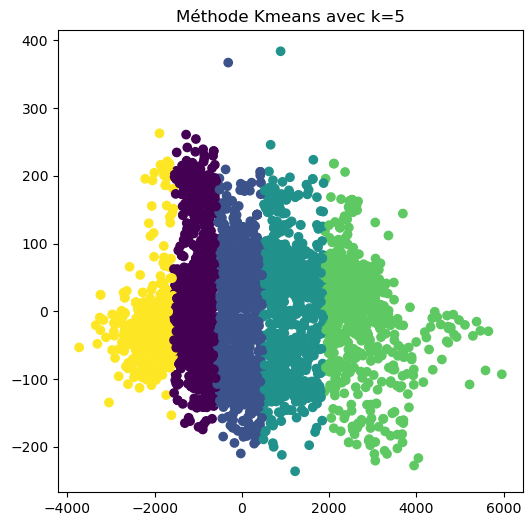

Accuracy: 40.30%
Score de performance : 0.403


/tmp/ipykernel_1070666/2166263020.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  number_labels[i] = reference_labels[y_pred_kmeans[i]]


In [10]:
# Application de la méthode K-means 

y_pred = KMeans(n_clusters=5, init='random').fit_predict(principalComponents)

print('Partition retournée',y_pred)

# Affichage des clusters
plt.figure(figsize=(6, 6))
plt.scatter(principalComponents[:, 0], principalComponents[:, 1], c=y_pred)
plt.title("Méthode Kmeans avec k=5")
plt.show()
labels = correspondance(y_pred,LabelApp.astype(np.int64))
accuracy = np.mean(labels == LabelApp)
print(f"Accuracy: {accuracy:.2%}")
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(labels, LabelApp))

# Classification bayésienne

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(principalComponents, LabelApp, test_size=0.20, random_state=42)

print('Dimension de la base apprentissage :',X_train.shape)
print('Dimension de la base test : ',X_test.shape)

from sklearn.naive_bayes import GaussianNB

# chargement du modèle et de ses paramètres
clf = GaussianNB()
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(X_train, y_train)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(X_test)

from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(y_test, y_pred_Bayes))

Dimension de la base apprentissage : (4000, 156)
Dimension de la base test :  (1000, 156)
Score de performance : 0.694


In [12]:
# Classification bayésienne 

from sklearn.model_selection import train_test_split

print('Dimension de la base apprentissage :',principalComponents.shape)
print(LabelApp.shape)
print('Dimension de la base test : ',principalComponentsTest.shape)
print(LabelTest.shape)


Dimension de la base apprentissage : (5000, 156)
(5000,)
Dimension de la base test :  (750, 156)
(750,)


Score de performance : 0.696
Score de performance Base d Apprentissage : 0.7008


1.0000000000000002

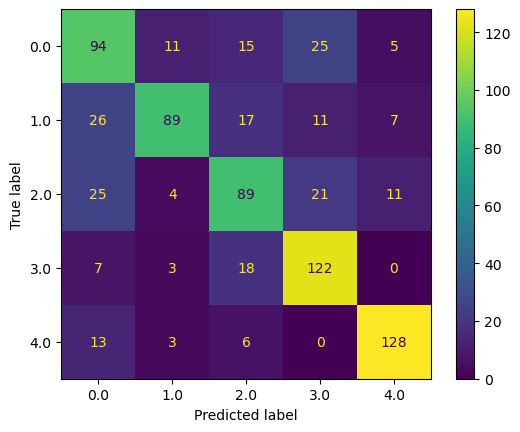

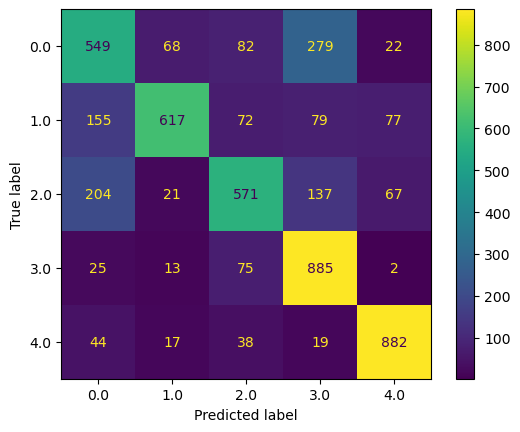

In [13]:
from sklearn.naive_bayes import GaussianNB

# chargement du modèle et de ses paramètres
clf = GaussianNB()

# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(principalComponents, LabelApp)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(principalComponentsTest)
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(LabelTest, y_pred_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelTest,y_pred_Bayes)

# Evaluation du modèle appris sur la base d'apprentissage 
y_pred_train_Bayes=clf.predict(principalComponents)

print('Score de performance Base d Apprentissage :',accuracy_score(LabelApp, y_pred_train_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelApp,y_pred_train_Bayes)
pca.explained_variance_ratio_.sum()


In [14]:
cat = ['Regroupée','Statistique','Temporelle','Spectrale']
score_test = []
score_base_app = []
score_moyenne_meilleure_combinaison=[]

Fitting 5 folds for each of 65 candidates, totalling 325 fits
Meilleure combinaison trouvée: {'nb__var_smoothing': 1e-08, 'pca__n_components': 37}
Meilleure précision moyenne sur les 5 plis de validation 0.7148
Score de performance : 0.7013333333333334
Score de performance Base d Apprentissage : 0.7218
Composantes retenues : 37
Variance expliquée   : 0.9542318646641754


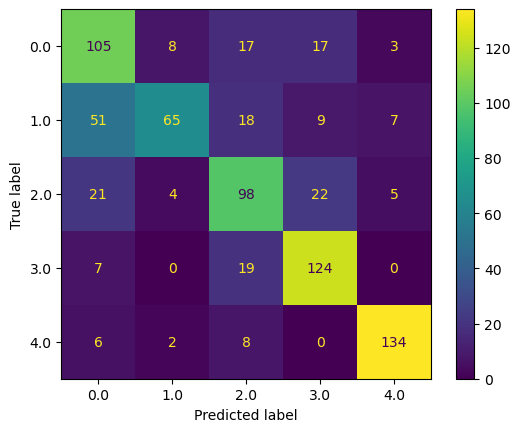

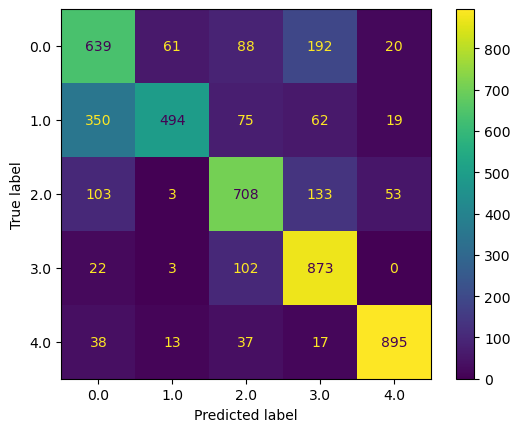

In [15]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('nb', GaussianNB())
])
params_NB = {
    'pca__n_components': [25, 30, 35, 37, 40],
    'nb__var_smoothing': np.logspace(-12, 0, 13)
}
clf = GridSearchCV(pipe,
                    param_grid=params_NB, 
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
                    verbose=1, 
                    scoring='accuracy',
                    n_jobs=-1)
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(DataFeatureApp, LabelApp)
print("Meilleure combinaison trouvée:",clf.best_params_)
print("Meilleure précision moyenne sur les 5 plis de validation",clf.best_score_)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(DataFeatureTest)
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(LabelTest, y_pred_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelTest,y_pred_Bayes)

# Evaluation du modèle appris sur la base d'apprentissage 
y_pred_train_Bayes=clf.predict(DataFeatureApp)

print('Score de performance Base d Apprentissage :',accuracy_score(LabelApp, y_pred_train_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelApp,y_pred_train_Bayes)

best_pca = clf.best_estimator_.named_steps['pca']

print('Composantes retenues :', best_pca.n_components_)
print('Variance expliquée   :', best_pca.explained_variance_ratio_.sum())

score_moyenne_meilleure_combinaison.append(clf.best_score_)
score_test.append(accuracy_score(LabelTest, y_pred_Bayes))
score_base_app.append(accuracy_score(LabelApp, y_pred_train_Bayes))


### Classification bayésienne naive gaussien sur les modalité statistique avec optimisation par recherche sur grille (GridSearchCV)

Fitting 5 folds for each of 117 candidates, totalling 585 fits
Meilleure combinaison trouvée: {'nb__var_smoothing': 1e-07, 'pca__n_components': 15}
Meilleure précision moyenne sur les 5 plis de validation 0.6782
Score de performance : 0.6613333333333333
Score de performance Base d Apprentissage : 0.6806
Composantes retenues : 15
Variance expliquée   : 0.9999993648699063


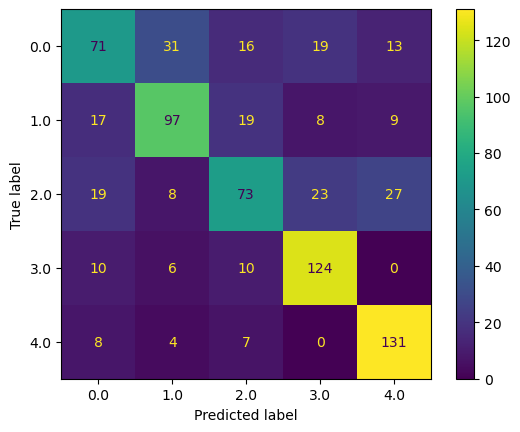

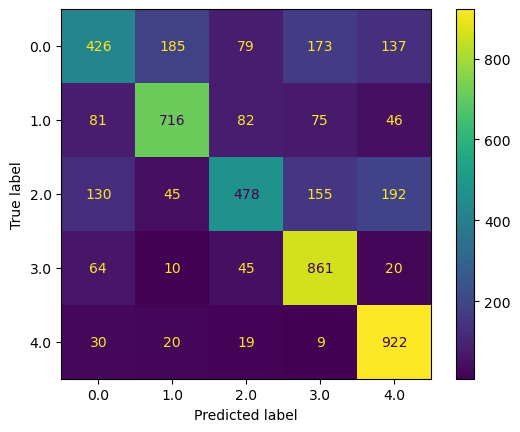

In [17]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.pipeline import Pipeline
pipe = Pipeline([
    ('pca', PCA()),
    ('nb', GaussianNB())
])
params_NB = {
    'pca__n_components': [2, 4, 8, 10, 12, 15, 17, 20, 25],
    'nb__var_smoothing': np.logspace(-12, 0, 13)
}
clf = GridSearchCV(pipe,
                    param_grid=params_NB, 
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
                    verbose=1, 
                    scoring='accuracy')
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(DataAppStat, LabelApp)
print("Meilleure combinaison trouvée:",clf.best_params_)
print("Meilleure précision moyenne sur les 5 plis de validation",clf.best_score_)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(DataTestStat)
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(LabelTest, y_pred_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelTest,y_pred_Bayes)

# Evaluation du modèle appris sur la base d'apprentissage 
y_pred_train_Bayes=clf.predict(DataAppStat)

print('Score de performance Base d Apprentissage :',accuracy_score(LabelApp, y_pred_train_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelApp,y_pred_train_Bayes)

best_pca = clf.best_estimator_.named_steps['pca']

print('Composantes retenues :', best_pca.n_components_)
print('Variance expliquée   :', best_pca.explained_variance_ratio_.sum())

score_moyenne_meilleure_combinaison.append(clf.best_score_)
score_test.append(accuracy_score(LabelTest, y_pred_Bayes))
score_base_app.append(accuracy_score(LabelApp, y_pred_train_Bayes))

### Classification bayésienne naive gaussien sur les modalité temporelle avec optimisation par recherche sur grille (GridSearchCV)

Fitting 5 folds for each of 65 candidates, totalling 325 fits
Meilleure combinaison trouvée: {'nb__var_smoothing': 1e-12, 'pca__n_components': 14}
Meilleure précision moyenne sur les 5 plis de validation 0.6704000000000001
Score de performance : 0.656
Score de performance Base d Apprentissage : 0.6734
Composantes retenues : 14
Variance expliquée   : 1.0


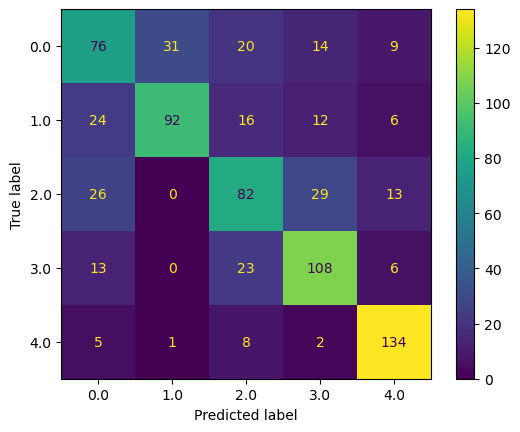

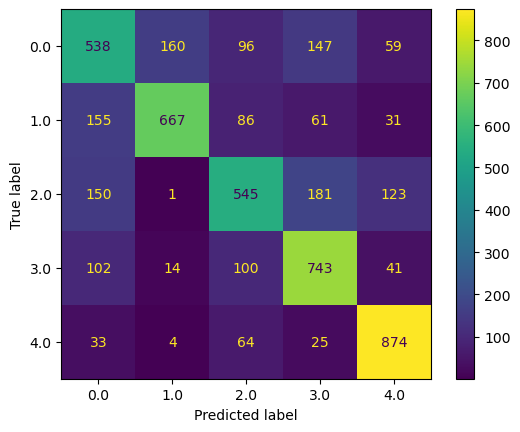

In [19]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.pipeline import Pipeline
pipe = Pipeline([
    ('pca', PCA()),
    ('nb', GaussianNB())
])
params_NB = {
    'pca__n_components': [2, 4, 8, 10, 14],
    'nb__var_smoothing': np.logspace(-12, 0, 13)
}
clf = GridSearchCV(pipe,
                    param_grid=params_NB, 
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
                    verbose=1, 
                    scoring='accuracy')
# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(DataAppTemps, LabelApp)
print("Meilleure combinaison trouvée:",clf.best_params_)
print("Meilleure précision moyenne sur les 5 plis de validation",clf.best_score_)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(DataTestTemps)
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(LabelTest, y_pred_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelTest,y_pred_Bayes)

# Evaluation du modèle appris sur la base d'apprentissage 
y_pred_train_Bayes=clf.predict(DataAppTemps)

print('Score de performance Base d Apprentissage :',accuracy_score(LabelApp, y_pred_train_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelApp,y_pred_train_Bayes)

best_pca = clf.best_estimator_.named_steps['pca']

print('Composantes retenues :', best_pca.n_components_)
print('Variance expliquée   :', best_pca.explained_variance_ratio_.sum())

score_moyenne_meilleure_combinaison.append(clf.best_score_)
score_test.append(accuracy_score(LabelTest, y_pred_Bayes))
score_base_app.append(accuracy_score(LabelApp, y_pred_train_Bayes))

### Classification bayésienne naive gaussien sur les modalité spectrale avec optimisation par recherche sur grille (GridSearchCV)

Fitting 5 folds for each of 65 candidates, totalling 325 fits
Meilleure combinaison trouvée: {'nb__var_smoothing': 1e-12, 'pca__n_components': 14}
Meilleure précision moyenne sur les 5 plis de validation 0.7114
Score de performance : 0.6773333333333333
Score de performance Base d Apprentissage : 0.7172
Composantes retenues : 14
Variance expliquée   : 0.9999995750156795


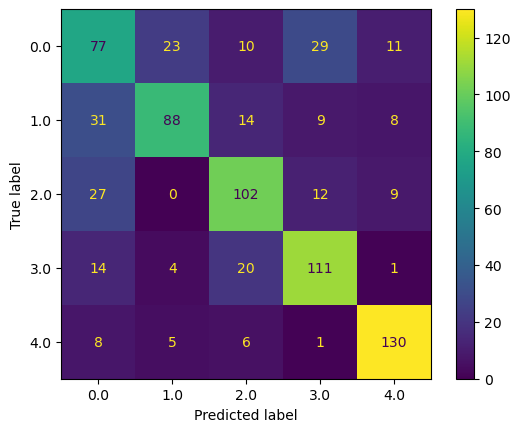

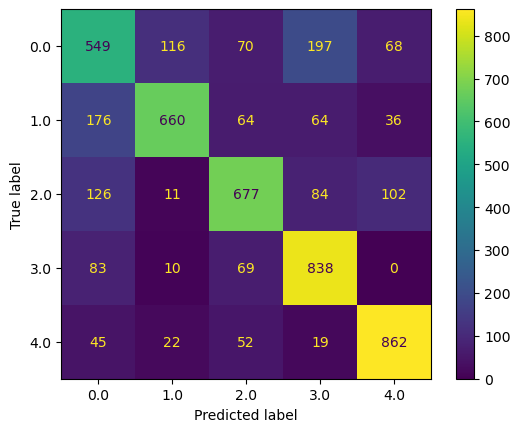

In [ ]:
from sklearn.model_selection import GridSearchCV,StratifiedKFold
from sklearn.pipeline import Pipeline
pipe = Pipeline([
    ('pca', PCA()),
    ('nb', GaussianNB())
])
params_NB = {
    'pca__n_components': [2, 4, 8, 10, 14],
    'nb__var_smoothing': np.logspace(-12, 0, 13)
}
clf = GridSearchCV(pipe,
                    param_grid=params_NB, 
                    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
                    verbose=1, 
                    scoring='accuracy')

# Apprentissage du modèle et de ses paramètres à l'aide des données étiquettées, 
# c'est-à-dire de la base d'apprentissage, X_train et de ses labels y_train
clf.fit(DataAppSpec, LabelApp)
print("Meilleure combinaison trouvée:",clf.best_params_)
print("Meilleure précision moyenne sur les 5 plis de validation",clf.best_score_)

# Une fois le modèle appris, on teste ce modèle sur un nouveau jeu de données X_test
y_pred_Bayes=clf.predict(DataTestSpec)
from sklearn.metrics import accuracy_score

# Evaluation de la performance du modèle à l'aide de la vérité terrain y_test
print('Score de performance :',accuracy_score(LabelTest, y_pred_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelTest,y_pred_Bayes)

# Evaluation du modèle appris sur la base d'apprentissage 
y_pred_train_Bayes=clf.predict(DataAppSpec)

print('Score de performance Base d Apprentissage :',accuracy_score(LabelApp, y_pred_train_Bayes))
ConfusionMatrixDisplay.from_predictions(LabelApp,y_pred_train_Bayes)

best_pca = clf.best_estimator_.named_steps['pca']

print('Composantes retenues :', best_pca.n_components_)
print('Variance expliquée   :', best_pca.explained_variance_ratio_.sum())

score_moyenne_meilleure_combinaison.append(clf.best_score_)
score_test.append(accuracy_score(LabelTest, y_pred_Bayes))
score_base_app.append(accuracy_score(LabelApp, y_pred_train_Bayes))

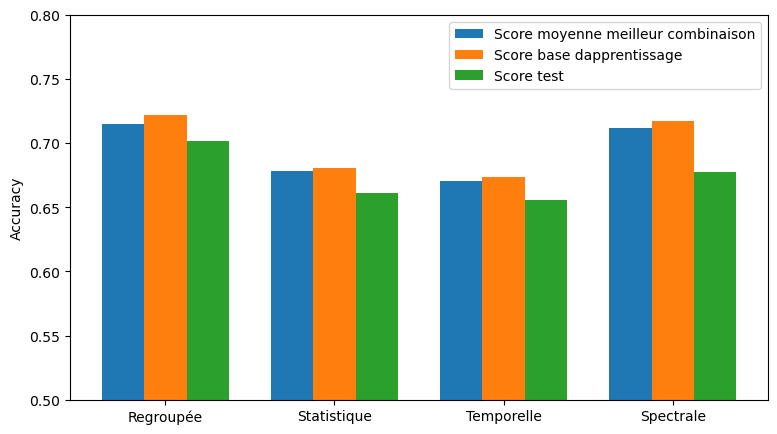

In [29]:

x = np.arange(len(cat))
w = 0.25
fig,ax = plt.subplots(figsize=(9,5))

ax.bar(x-w,score_moyenne_meilleure_combinaison,width=w,label='Score moyenne meilleur combinaison')
ax.bar(x,score_base_app,width=w, label='Score base d''apprentissage' )
ax.bar(x+w, score_test,width=w,label='Score test')

ax.set_xticks(x)
ax.set_xticklabels(cat)
ax.set_ylabel("Accuracy")
ax.set_ylim(0.5, 0.8)  
ax.legend()

plt.show()


# Réaliser votre étude :

- Etudier les meilleurs paramètres pour les méthodes supervisées et non supervisées que vous avez choisies.
- Faire une étude sur les paramètres issus de TSFEL en séparant par exemple les différentes modalités (statistiques,temporelles et spectrales) ou en étudiant leur correlation et essayer de réaliser des prétraitements.
- Optimiser la réduction de dimensions par ACP
